# This this the tutorial notebook to help you use FAMILY 

## Prerequisites

The tutorial is based on the benchmark dataset you can find in the github repo. More information on how this benchmark data are created can be find in the dedicated notebook. For each angular resolution, check that you have :

1. The catalog : in this tutorial this is a .csv table. You can use any table format you want as long as you can provide a function to read it and convert it into a pandas DataFrame.
2. The config file : in .toml format. It is used to interpret the columns of one table. For example, what labels are the X and Y coordinates, what are the conversion factors and indicate other header informations about the data you provide.
3. Optional : the .fits image from which your structures are extracted from, or whatever background image is associated to your dataset.
4. Optional : A region of your background image that represent the field of view in which the structures of your catalog are extracted.

## Prepare your data

### Create your environement

### Open the data

If you already have your files created, locate where it is and open it.

In [1]:
from pathlib import Path
path = Path("./benchmark/polygons_xy/config/").resolve()

### Define a reading function

The function needs to return a pandas DataFrame

In [2]:
import pandas as pd
reader = lambda x: pd.read_csv(x, delimiter=",", comment="#")

### After you configured all the config files

You need to instantiate Data class objects and put them into a DataSet class object.
Each table is associated to one Data object. Their association constitutes the DataSet object. This object is just an aggregator of Data.

In [3]:
from analysis import analyse

dataset = analyse.DataSet(
    analyse.Data(config, reader_to_df=reader)
    for config in path.glob("*.toml")
)

#### Attributes of Data class

- 'path': path of the config file that is used to read the data
- 'df': normalised dataframe the code reads
- 'comment': any comment in the config file
- 'catalog': origin of catalog file
- 'fits_img': fits image from which the objects are extracted
- 'beam': observation beam (in arcsec)
- 'wavelength': wavelenght of observation (in µm)
- 'distance': distance of the region (in pc)
- 'fov_window': polygon object that define the field of view of extraction (-1 if all image is used)
- 'color': color used to represent the data in the figures

#### Check up

After aggregating all your catalogs you can have a look at the number of elements :

In [4]:
for name, data in dataset.items():
    print(f"sample {name} : {len(data.df)} elements")
    
print(f"total #elements = {sum(data.df.shape[0] for data in dataset)}")

sample L01 : 24 elements
sample L02 : 35 elements
sample L03 : 51 elements
sample L04 : 66 elements
sample L05 : 89 elements
total #elements = 265


## Reconstruct the parentality (i.e. the network)

In [5]:
network = analyse.Network(dataset, min_overlap=0.8)

### Show the network properties

By printing the network you can look at its main properties :
- Minimum overlap between parent and children used to build the parentality
- Number of nodes (i.e. objects)
- Number of edges (i.e. spatial overlap between each object)
- Number of component (i.e. number of disconnected sub-graph). *We come back to this at [Section : Extract the structures.](#Extract-the-structures)*
- Levels used to build the network

**Note that there are 10 disconnected components in this network.**

In [6]:
print(network)

Network
min_overlap - 0.8
n_nodes - 265
n_edges - 248
n_components - 24
levels - (0.13, 0.2, 0.3, 0.44, 0.67)


### DataFrame view

You can have a DataFrame view of the network with its main characteristics. Note that we have a total of 74 line, which corresponds to the total number of objects in our benchmark dataset.

In [7]:
from analysis import network_utility as utility
clumps = utility.toDataFrame(network.network)
clumps

,_Kind,_beam,_X,_level,_Polygon,_Holes,_Fractality,_Y
0,NodeKind.SINK,0.13,"[-16.536709362102616, -16.53234792703461, -16....",0,POLYGON ((-16.536709362102616 0.58363802542542...,0,None,"[0.5836380254254292, 0.5791826412118403, 0.574..."
1,NodeKind.SINK,0.13,"[2.053943434729476, 2.0562518961409637, 2.0588...",0,"POLYGON ((2.053943434729476 17.1031441641081, ...",0,None,"[17.1031441641081, 17.10763980800809, 17.11201..."
2,NodeKind.SINK,0.13,"[-6.942824378846872, -6.9448666833973345, -6.9...",0,POLYGON ((-6.942824378846872 -12.0325880652102...,0,None,"[-12.032588065210293, -12.027104297968013, -12..."
3,NodeKind.SINK,0.13,"[15.238574225473137, 15.244337164081047, 15.25...",0,POLYGON ((15.238574225473137 -2.32892700024039...,0,None,"[-2.3289270002403915, -2.325308560114295, -2.3..."
4,NodeKind.SINK,0.13,"[3.713225254710447, 3.7122484545661183, 3.7109...",0,POLYGON ((3.713225254710447 -18.69207120394875...,0,None,"[-18.692071203948753, -18.699835746829816, -18..."
...,...,...,...,...,...,...,...,...
260,NodeKind.SOURCE,0.67,"[-16.612169629850968, -16.663178187074852, -16...",4,POLYGON ((-16.612169629850968 1.58964346702002...,0,[1.7783561299344492],"[1.5896434670200226, 1.5938916727938457, 1.595..."
261,NodeKind.SOURCE,0.67,"[-3.9753280939076197, -3.9928804622182152, -4....",4,POLYGON ((-3.9753280939076197 -12.397849824929...,0,[2.1555637611505722],"[-12.397849824929846, -12.444918640958637, -12..."
262,NodeKind.SOURCE,0.67,"[7.365053311932726, 7.334947588432698, 7.30325...",4,POLYGON ((7.365053311932726 -8.019237896455055...,0,[1.8795330143518074],"[-8.019237896455055, -7.992737566992718, -7.96..."
263,NodeKind.SOURCE,0.67,"[-1.3249997072897237, -1.3475464092183822, -1....",4,POLYGON ((-1.3249997072897237 -11.359567022019...,0,[0.9999999999999999],"[-11.359567022019998, -11.382829072210145, -11..."


## Extract the structures

In our network we have 10 disconnected components. Which means that there is 10 sub-network whose elements don't spatially overlap. This is the number of independant multi-scale structure. We can extract these multi-scale structures and compute their fractality individually.

In [8]:
network.extractStructures()

### Show the structures properties

The attribute network.structures now contains a list of Structure objects. Each Structure object contains information about the structure, such as :
- component : The label of the nodes it is composed of
- sinks : the number of sinks (nodes without child)
- sources : the number of sources (nodes without parents)
- mode : hierarchical, linear or isolated
- fractality : related to the fragmentation spatial rate
- missed : number of holes in the network
- percmissed : number of missed in % of the total number of nodes
- maxR : biggest resolution available in this structure
- YSO : number of YSO
- gas : number of gas structures (cores/ellipsoids)

If you want to have a propoer table view of these structures, you can do this :

In [9]:
structure_table = network.getStructuresTable()
structure_table

,component,sinks,sources,mode,fractality,missed,percmissed,maxR,YSO,gas,polygon,size,xposition,yposition
0,"(0, 129, 163, 196, 260, 238, 110, 144, 22, 87,...",4,1,HIERARCHICAL,1.778356,3,0.214286,0.67,0,6,POLYGON ((-16.52067896634339 1.577923191096519...,1.914756,-16.705873,0.528288
1,"(160, 1, 197, 70, 103, 7, 37, 38, 145, 242, 93...",5,1,HIERARCHICAL,2.067575,0,0.000000,0.67,0,8,"POLYGON ((1.811671043857562 17.19392288375447,...",1.978351,2.940153,17.338090
2,"(225, 2, 185, 68, 165, 170, 107, 80, 116, 118,...",3,2,HIERARCHICAL,1.654193,2,0.142857,0.67,0,7,POLYGON ((-7.098107529963785 -11.5044758611957...,1.548616,-6.600368,-12.296302
3,"(3, 146, 147, 40, 42, 56, 186, 187, 188, 66, 2...",6,1,HIERARCHICAL,2.476334,0,0.000000,0.67,0,12,POLYGON ((14.426625452959643 -2.90002399255085...,2.277785,14.222568,-1.881194
4,"(4, 133, 212, 181, 246)",1,1,LINEAR,1.000000,0,0.000000,0.67,0,3,POLYGON ((2.6311928117403003 -17.7252219082504...,1.637367,3.322830,-18.436849
5,"(226, 34, 5, 102, 262, 91, 235, 109, 21, 184, ...",4,1,HIERARCHICAL,1.879533,0,0.000000,0.67,0,7,"POLYGON ((5.759033466713559 -8.98155724856244,...",1.668885,6.726996,-8.767009
6,"(230, 6, 263, 174, 115)",1,1,LINEAR,1.000000,0,0.000000,0.67,0,3,POLYGON ((-1.1936173466315432 -12.457609675505...,1.442102,-0.785002,-12.011047
7,"(36, 8, 202, 140, 15, 211, 180, 245, 151)",3,1,HIERARCHICAL,1.557735,2,0.181818,0.67,0,5,POLYGON ((4.604648304422188 -5.642175627917203...,1.537405,3.862950,-5.229805
8,"(9, 11, 77, 208, 177, 85, 183, 90, 252, 95)",4,1,HIERARCHICAL,1.671423,0,0.000000,0.67,0,5,POLYGON ((6.997635070654259 3.6894518596737784...,1.566892,7.662524,4.374410
9,"(99, 10, 239, 54, 248, 89, 157)",2,1,HIERARCHICAL,1.304342,0,0.000000,0.67,0,4,POLYGON ((-0.1081404493589638 -15.847753141249...,1.786540,0.373968,-16.686039


### View the structures 

#### Using the interactive applet

You may want to inspect all the structures or the network. In this tkinter window you can look at the structures in their physical form and compare them to the equivalent network. You can change the background and add some colors too!

#### Using static plots

Here are more regular graphics. You select the background and plot a specific structure.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


INFO: Auto-setting vmin to  3.846e-53 [aplpy.core]
INFO: Auto-setting vmax to  4.482e+01 [aplpy.core]


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


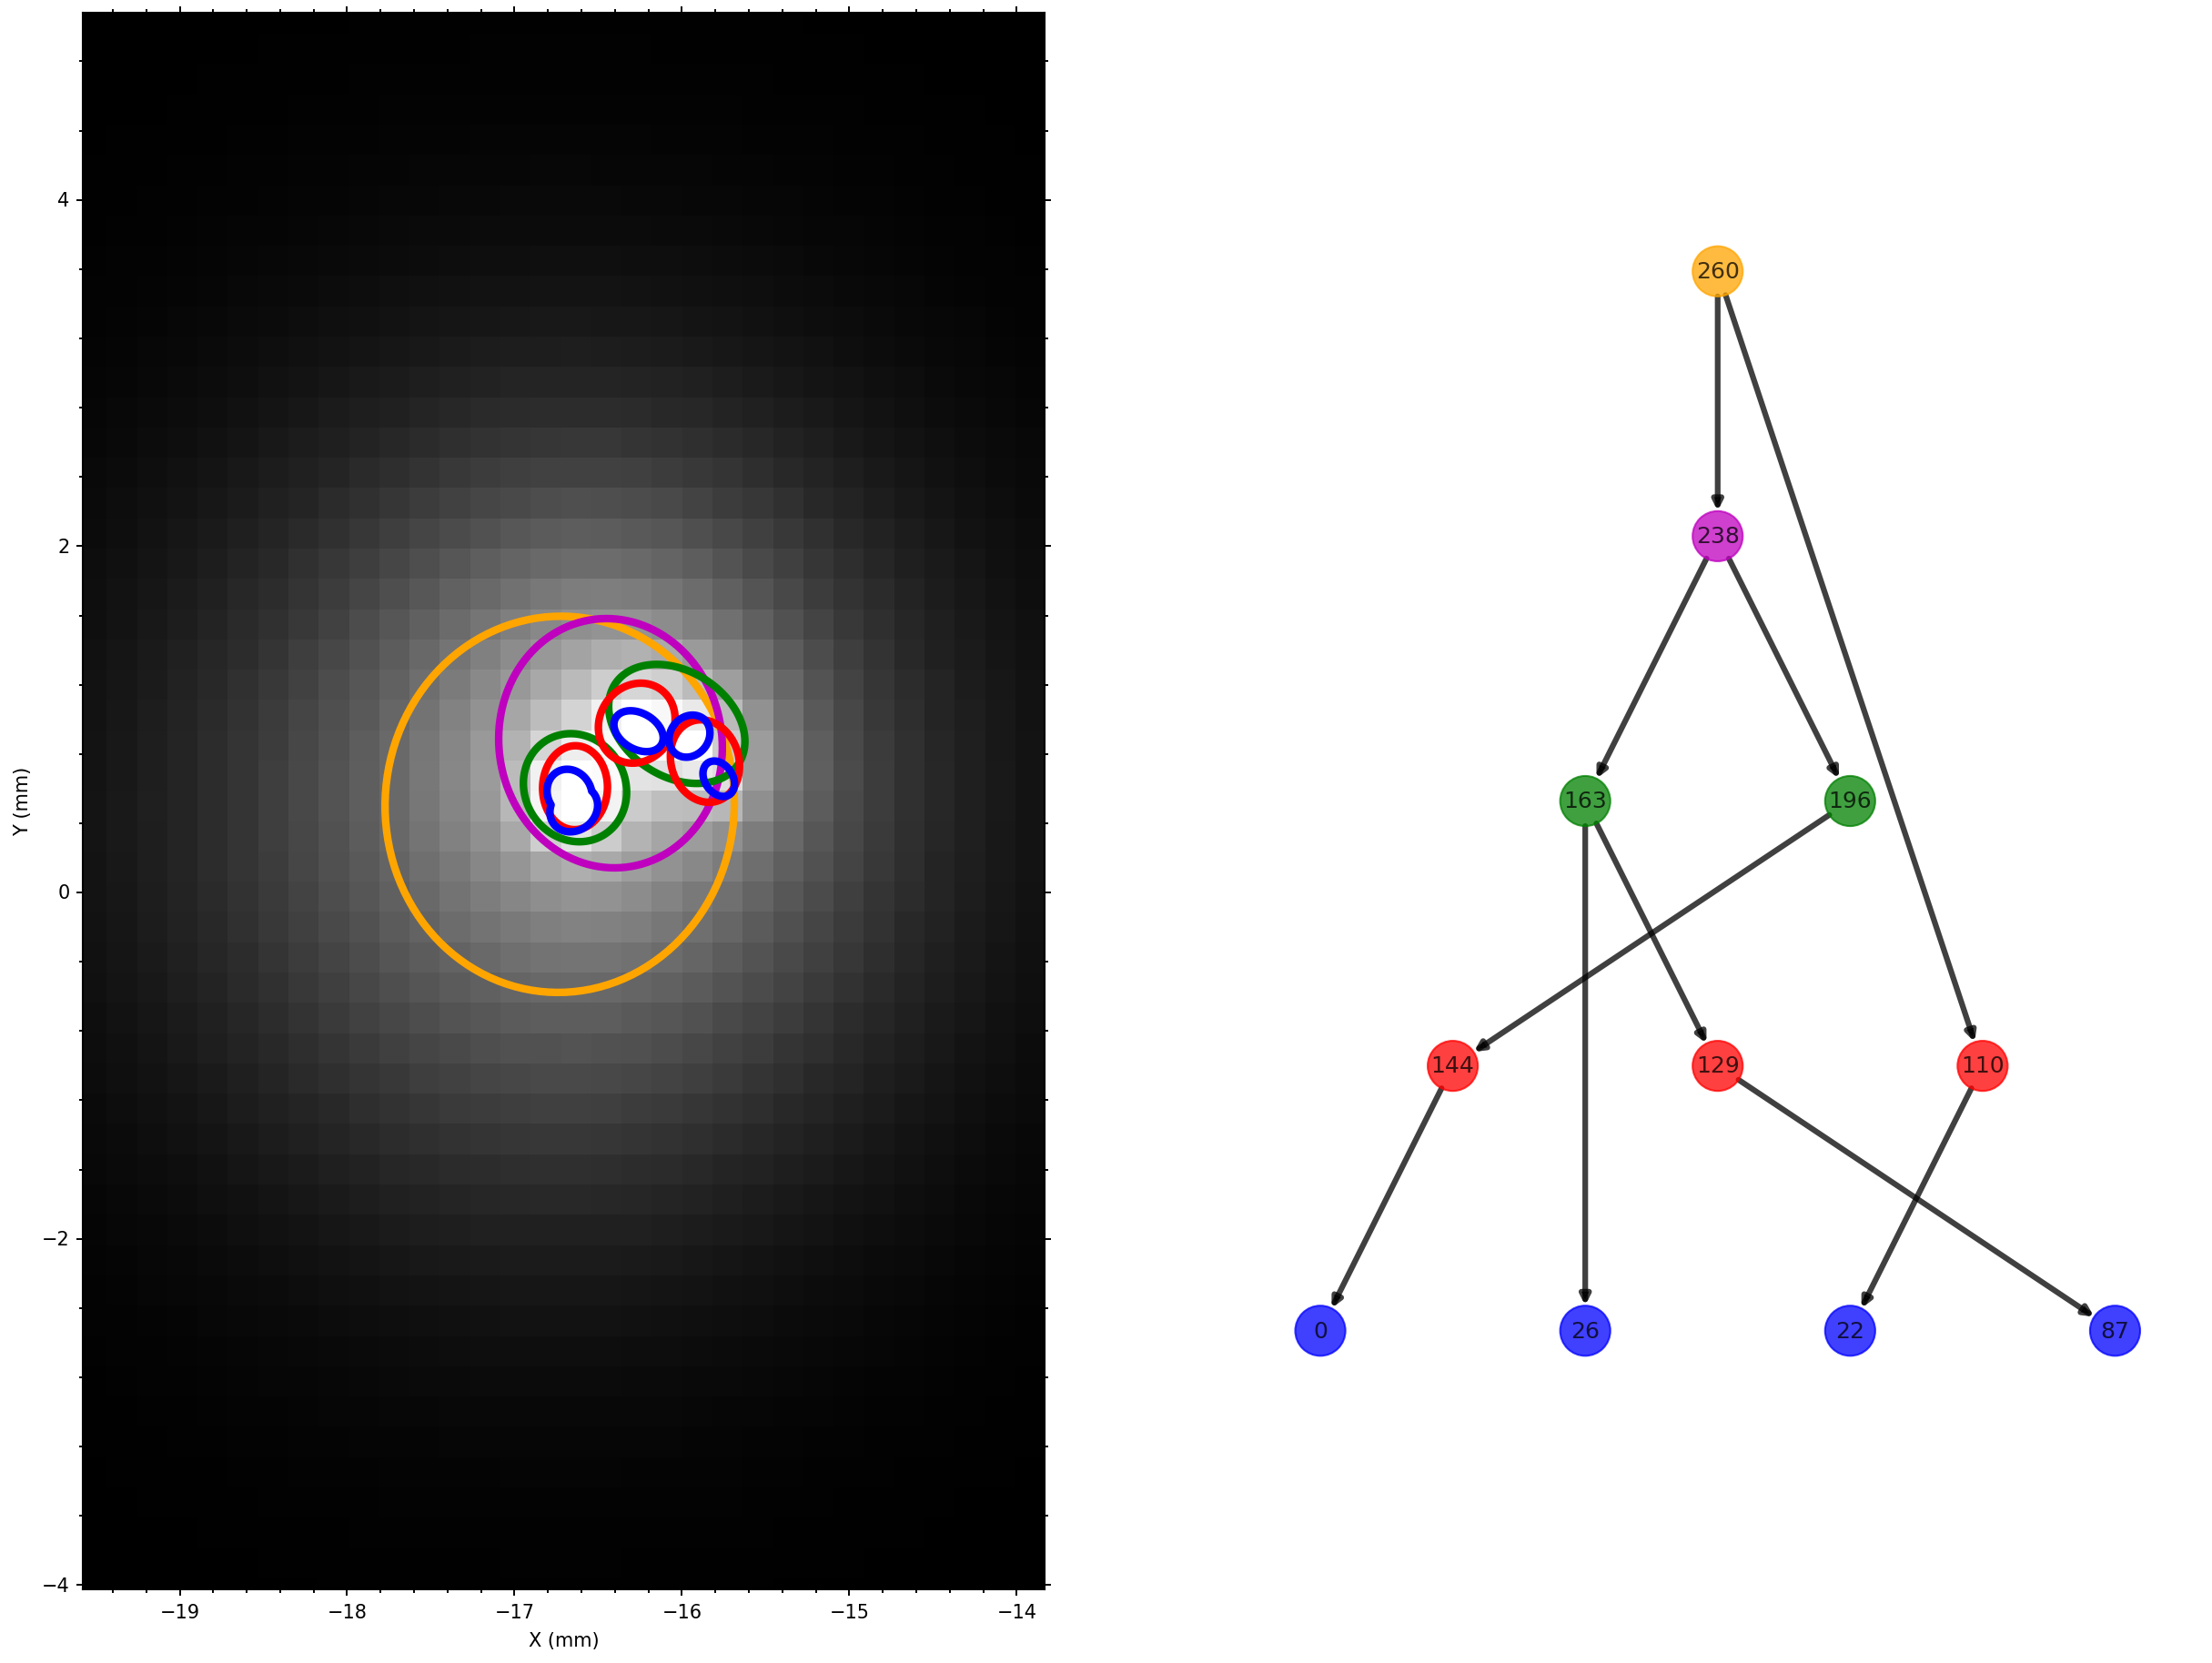

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams['figure.dpi'] = 150 

image = dataset["L01"].fits_img
fig = network.structures[0].plot(image)
plt.show()

## Measurement of the fractal index

Below a small procedure to analyse the fractality index and its uncertainty. Then how to use it to estimate the 3D fragmentation spatial rate. If you care to know where does the uncertainty comes from, and how fractality is measured, read the tutorial below. Else, you can just skip the tutorial until [the summary](#Fragmentation-rate-computation-summary).

### Raw measurement

#### What is the fractal index $\mathcal{F}$ ?

It represents the number of substructures produced each time the spatial scale is reduced by a factor of two in an ideal fractal network.

Suppose you have a tree network structured in discrete levels associated with spatial scales. To calculate it, we first count the total number of nodes $V_0$ in the observed network. Next, we consider an ideal fractal network with the same spatial scales and $V$ nodes. If this ideal network contains the same total number of nodes ($V = V_0$), then its fractal index $\mathcal{F}$ can characterise the average subdivision of the observed network, if it was fractal. Since the number of nodes in the ideal fractal network is :

$$
V = \sum_{l=0}^{L-1} \mathcal{F}^{\frac{\ln(R_0/R_l)}{\ln(2)}}
$$

We need to solve:

$$
V_0 - \sum_{l=0}^{L-1} \mathcal{F}^{\frac{\ln(R_0/R_l)}{\ln(2)}} = 0
$$

$\mathcal{F}$ is the root solution of this equation and is determined numerically.


#### Fractality of a whole population

Although fragmentation is a continuous process, its representation as a network is discrete. Therefore, statistical analysis helps characterise fragmentation across a population of networks. The fractal index is bounded by $\mathcal{F}=1$ as its lowest value, so its distribution is skewed. The median can provide a more representative measure of typical behavior than the mean, which is more sensitive to large values.

Sample selection should also account for the different fragmentation regimes: hierarchical, linear, and isolated (Thomasson et al., 2024). Linear structures have $\mathcal{F}=1$ by definition. If your goal is to characterize the hierarchically fragmenting subpopulation, only hierarchical structures should be included in the analysis.

In [11]:
import numpy as np

fractalities = [struct.fractality for struct in network.structures]
print(f"Mean : {np.mean(fractalities)}\nMedian : {np.median(fractalities)}")

Mean : 1.7240639531261976
Median : 1.7248896385748265


If you want to take only the hierarchical structures (linears always give 1), be aware that struct.mode containe an Enum object that maps the name - value like this :

&emsp;**ISOLATED = 1**\
&emsp;**LINEAR = 2**\
&emsp;**HIERARCHICAL = 3**


So, you need to filter the structures like this :

In [12]:
fractalities = [struct.fractality for struct in network.structures if struct.mode.name == "HIERARCHICAL"]
print(f"Mean (Hierarchical only) : {np.mean(fractalities)}\nMedian (Hierarchical only) : {np.median(fractalities)}")

Mean (Hierarchical only) : 1.8275016607156545
Median (Hierarchical only) : 1.7783561299344492


### Visualise the distribution

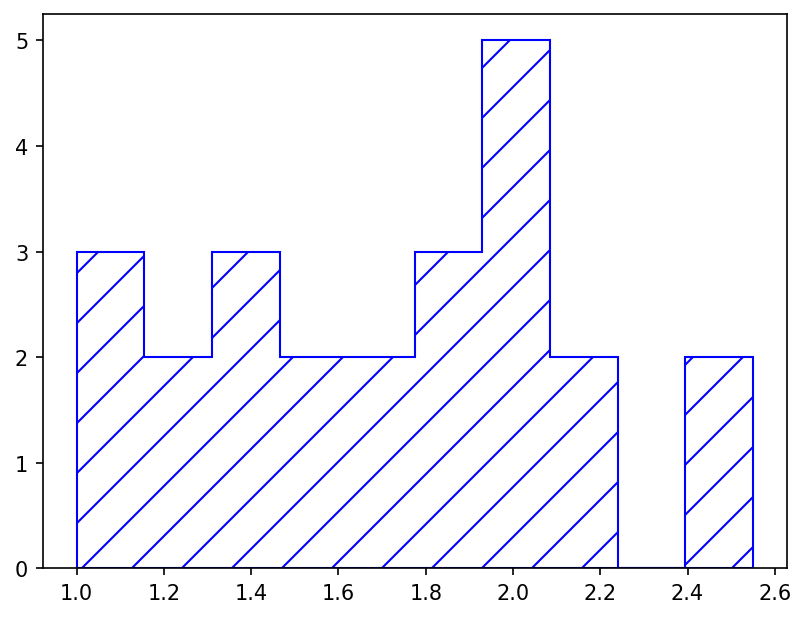

In [13]:
fractalities = [struct.fractality for struct in network.structures]

_ = plt.hist(fractalities, bins=10, edgecolor="b", histtype='stepfilled', fill=False, hatch='/')

### Productivity of fragments

For one structure, the productivity gives the ratio between the number of fragments at level $l$ and the number of sources in the structure. For all the structures, this shows the average productivity.

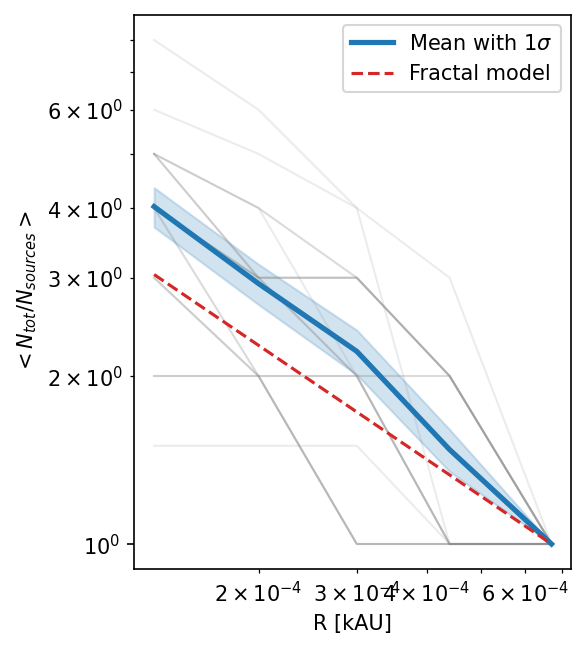

In [14]:
from analysis import plotter

distance = network.data["L01"].distance
x, meany, stdy, y = plotter.getFragCurve(network, distance, mode = "HIERARCHICAL")

fig, ax = plt.subplots()
x_kau = x / 1000

# individual structures
for serie in y:
    ax.plot(x_kau, serie, color="gray", alpha=0.15, linewidth=1)

ax.fill_between(
    x_kau, meany - stdy, meany + stdy,
    color="tab:blue", alpha=0.2
)
ax.plot(x_kau, meany, color="tab:blue", linewidth=2.5, label="Mean with 1$\\sigma$")

# If fragmentation is fractal, productivity should follow this law
fractality = 1.6
exponent = -(np.log(fractality)/np.log(2))
y_fractal = (x / max(x))**exponent
ax.plot(x_kau, y_fractal, "--", color="tab:red", label="Fractal model")

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("R [kAU]")
ax.set_ylabel("$<N_{tot}/N_{sources}>$")
ax.set_aspect("equal", adjustable="box")
ax.legend()

## The 2D average fragmentation spatial rate $\overline{\phi_{2D}}$

### How to derive it ?

In two dimensions, the average fragmentation spatial rate $\overline{\phi_{2D}}$ is, by definition, related with the fractality metric using the following :

$$
\overline{\phi_{2D}} = \frac{\ln \mathcal{F}}{\ln 2}
$$

Where log is the natural logarithm (base $e$). Since $\mathcal{F}$ is averaged over the full spatial range, the corresponding fragmentation rate is also averaged over this range, as indicated by the bar notation. The associated uncertainty is given by:

$$
\Delta \overline{\phi_{2D}} = \frac{\Delta \mathcal{F}}{\mathcal{F} \ln 2}
$$

### The median as an estimator

Because we are dealing with small samples of cores, the procedure is to apply these formulae on the median fractality taken from the whole sample of structures.  This approach therefore **assumes that all structures undergo the same fragmentation process**. The fractality you obtained is measured without accounting for the missing nodes inside the network. These missing nodes may result from:

- Limitations of the core extraction tool
- The absence or non-detection of an object at the resolution or wavelength used
- Noisy data
- Other possible causes

### What if structures undergo different fragmentation processes?

You can divide your sample into subsamples of cores with similar environments, locations, masses, or other relevant properties to group structures likely to share similar fragmentation behaviour. FAMILY can then be applied to each subsample separately.

A more general approach would be to measure $\phi_{\mathrm{2D}}$ for each structure individually, rather than assuming that all structures share the same fragmentation properties. This approach is not currently implemented.

### Number of missing detections

You can construct a graph with new virtual nodes filling the holes:

In [15]:
from analysis import network_utility as utility

virtual = utility.virtualNodes(network.network, network.levels)

Then recompute the fractalities, extract the structures and see what changed

In [16]:
network_filled = analyse.Network(network.data, min_overlap=network.min_overlap, graph=virtual)
utility.fractality(network_filled.network)

network_filled.extractStructures()

fractalities = [struct.fractality for struct in network.structures if struct.mode.name == "HIERARCHICAL"]
fractalities_filled = [struct.fractality for struct in network_filled.structures if struct.mode.name == "HIERARCHICAL"]

print("median with virtual nodes", np.median(fractalities))
print("median without virtual nodes", np.median(fractalities_filled))

median with virtual nodes 1.7783561299344492
median without virtual nodes 1.9757325782586452


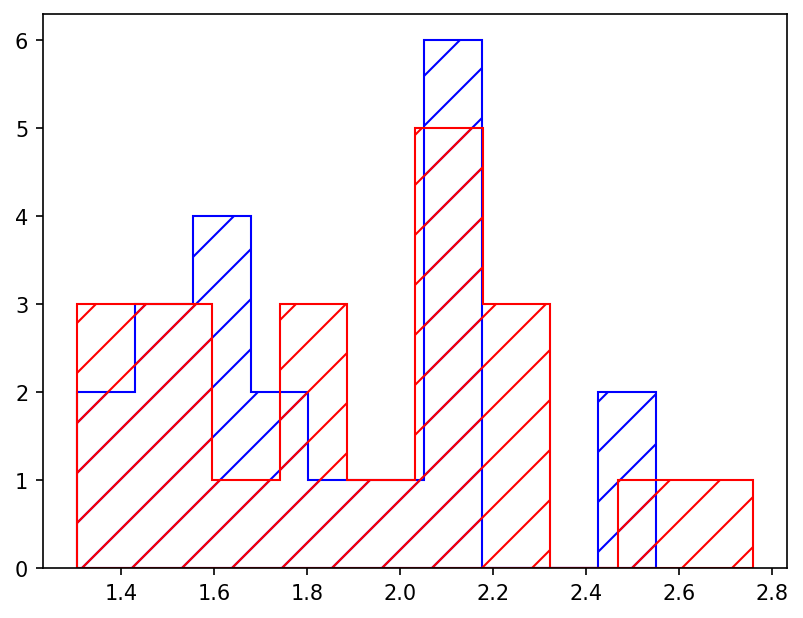

In [17]:
_ = plt.hist(fractalities, bins=10, edgecolor="b", histtype='stepfilled', fill=False, hatch='/')
_ = plt.hist(fractalities_filled, bins=10, edgecolor="r", histtype='stepfilled', fill=False, hatch='/')

### Median uncertainty

We compute a 68.27% confidence interval for the median ($\pm 1\sigma$). In previous studies (Thomasson et al. $\lt 2026$), the sample median was reported without an associated uncertainty, even though it may differ from the true median of the underlying stochastic fragmentation process. The uncertainty used to be accounted only for holes in the network, as described [hereafter](#Lower-and-Upper-bounds).

In [18]:
from scipy import stats

ci = stats.quantile_test(fractalities, p=0.5).confidence_interval(
            confidence_level=0.682689492
        )

print(f"Median : {np.median(fractalities):.3f}")
print(f"Confidence interval at 1 sigma : [{ci.low:.3f}, {ci.high:.3f}]")

Median : 1.778
Confidence interval at 1 sigma : [1.654, 2.068]


### Lower and Upper bounds

We treat the fractality from the observed network as a lower fractality range (valid as long as we consider that the sample undergoes the same fragmentation process). The upper range is obtained by computing the fractality after filling all holes in the graph. With the work done on the median, you have an estimation for the lower (median with holes) $\mathcal{F}_{low}$ and upper bound (median without holes) $\mathcal{F}_{up}$. You may want to select the fractality as varying inside this range :

$$
\mathcal{F} = \frac{\mathcal{F}_{up} + \mathcal{F}_{low}}{2}
$$

$$
\Delta \mathcal{F} = \frac{\mathcal{F}_{up} - \mathcal{F}_{low}}{2}
$$

In [19]:
from scipy import stats

ic = stats.quantile_test(fractalities, p=0.5).confidence_interval(
            confidence_level=0.682689492
        )

ic_filled = stats.quantile_test(fractalities_filled, p=0.5).confidence_interval(
    confidence_level=0.682689492
)

In [20]:
from analysis import fragmeasurement as fm

# old way of computing the uncertainty, less conservative
#f_up = np.median(fractalities_filled)
#f_low = np.median(fractalities)

f_up = ic_filled.high
f_low = ic.low

fractality, delta_fractality = fm.estimated_f(f_up, f_low)
phi2D = fm.phi2D(fractality)
delta_phi2D = fm.delta_phi2D(fractality, delta_fractality)

print(f"Fragmentation rate in 2D : {phi2D:.3f} +/- {delta_phi2D:.3f}")

Fragmentation rate in 2D : 0.896 +/- 0.160


## Fragmentation rate computation summary

One line computation once you understand where the uncertainty comes from.

In [21]:
# if you want to old way of computing uncertainties (without accounting for the median uncertainty), use:
# fm.compute_fractality(network, mode="legacy")
fractality, delta_fractality = fm.compute_fractality(network)
print(f"Fractality : {fractality:.3f} +/- {delta_fractality:.3f}")

# or if you want directly the 2D fragmentation rate :
# fm.compute_phi2d(network, mode="legacy")
phi2D, delta_phi2D = fm.compute_phi2d(network)
print(f"Fragmentation rate in 2D : {phi2D:.3f} +/- {delta_phi2D:.3f}")

Fractality : 1.861 +/- 0.207
Fragmentation rate in 2D : 0.896 +/- 0.160


## 3D fragmentation rate

### Projection and statistical uncertainties

The fragmentation rate you measured is a two dimensional metric. You can use the Julia notebook located in /model/geometrical_jl/synthetic.ipynb to generate a population of ellipsoid in 3D, project them in 2D and evaluate the relative difference $\psi$ between the fragmentation rates, define as :

$$
\psi = \frac{\overline{\phi_{2D}} - \overline{\phi_{3D}}}{\overline{\phi_{3D}}}
$$

You can then invert the equation to estimate the 3D fragmentation rate corresponding to a measured 2D fragmentation rate:

$$
\overline{\phi_{3D}} = \frac{\overline{\phi_{2D}}}{1 + \psi}
$$

The associated uncertainty is given below, where $\Delta\psi$ is the statistical uncertainty in the relative difference $\psi$. If $\psi$ is estimated from a plot/chart, you might want to consider the uncertainty due to the graphical reading when estimating $\Delta\psi$ :

$$
\Delta \overline{\phi_{3D}} =
\sqrt{
    \left(\frac{\Delta \overline{\phi_{2D}}}{1+\psi}\right)^2
    +
    \left(
        \frac{\overline{\phi_{2D}}}
        {(1+\psi)^2} \Delta \psi
    \right)^2
}
$$

Below an example of the kind of plot you may use (you can select multiple scaling ratios).

In [22]:
tables_path = "benchmark/simulation/projection_uncertainty.h5"

In the plot below you can see the uncertainties associated with projection effects. You can change the scaling_ratio, the minimum overlap for which a child is considered inside its parent, and the sample size. These data points are obtained from a simulation in the model/geometrical_jl project. It randomly samples $10^4$ ellipsoids in 3D given the scaling ratio, overlap and fragmentation rate, project the ellipsoids in 2D and recompute the average 2D fragmentation rate. The uncertainty is estimated by dividing the mean value with $\sqrt{N}$.

In [23]:
from analysis.visualise_uncertainties import explore_projection

explore_projection(tables_path)

explore_projection(
    tables_path,
    target_n=len([struct for struct in network.structures if struct.mode.name == "HIERARCHICAL"]), # Your sample size
    scaling_indices=[0, 1, 2],
)

### Interpretation of the plots above

#### What 3D fragmentation rate corresponds to your 2D measurement?

Given a measured fragmentation rate $\phi_{\mathrm{2D}}$, the plots allow you to estimate the corresponding range of $\phi_{\mathrm{3D}}$ for a given overlap and scaling ratio. Depending on the overlap and scaling ratio, a single 2D measurement may correspond to several possible 3D fragmentation rates, because of projection effects.

For example, in the context of this tutorial :
- overlap = 0.8
- scaling ratio r = 1.6
- phi2d = 0.896 $\pm$ 0.160

So by reading the graphics we have $\psi \approx -0.25 \pm 0.05$, with our sample N = 21, which gives $\phi_{3D} = 1.19 \pm 0.57$. These benchmark data were constructed with $\phi_{3D} = 1$. With a bigger sample, the uncertainty would reduce.

In [24]:
from analysis import fragmeasurement as fm

# what you measured
# phi2D, delta_phi2D

# what you can read on the plot, obtained using the julia notebook
relative_error = -0.25
delta_relative_error = 0.33

phi3D = fm.phi3D(phi2D, relative_error=relative_error)
delta_phi3D = fm.delta_phi3D(phi2D, delta_phi2D, relative_error, delta_relative_error)

print(f"Fragmentation rate in 3D : {phi3D:.2f} +/- {delta_phi3D:.2f}")

Fragmentation rate in 3D : 1.19 +/- 0.57


#### What range of fragmentation rates can you reliably measure?

Given the available spatial resolutions, you can estimate the range of $\phi_{\mathrm{3D}}$ you can measure, and with what precision. Don't hesistate to visualise the projection uncertainties with a sample $N = 10000$ to reduce errorbars.

For example, a measured fragmentation rate of $\phi_{\mathrm{2D}} = 1.7$ and an overlap of $0.8$ correspond to $\phi_{\mathrm{3D}}$ values ranging from approximately $2.2$ to $3.0$. Under these conditions, measurements with $\phi_{\mathrm{2D}} < 1.7$ allow more precise estimates of the 3D fragmentation rate.

#### What scaling ratio should you target?

If the scaling ratio $r$ is too small (e.g. $1.2$), the results become sensitive to the limitations of your extraction method, particularly its ability to contour child structures within their parent, or outside them. On the other hand, if $r$ is too large, you may miss intermediate levels of possible hierarchy.

The goal is to choose the smallest scaling ratio for which the geometrical constraints of the extraction method have little influence on the measured fragmentation rate.

For an extraction method in which child contours can extend beyond their parent contour, suppose a maximum overlap of $0.8$. Then, the minimum scaling ratio you would choose is approximately $r = 1.6$. Increasing $r$ beyond this value provides little improvement in the uncertainty of $\phi_{\mathrm{3D}}$. Keeping $r$ near this threshold allows you to probe the hierarchy more effectively while limiting geometrical biases.

Another example : for a maximum overlap of $0.7$, $r = 1.4$ can be considered a lower limit, as distinct $\phi_{\mathrm{3D}}$ values no longer produce the same $\phi_{\mathrm{2D}}$ in the range shown.

## Compare your value with a theoretical model

The directory "model" contains the scripts "semianalytical.py" and "figures.py" that compute and display the 3D fragmentation rate computed using the model from Thomasson et al. 2024. This model gives you the instanteneous fragmentation rate. You previously measured the fragmentation rate averaged over a range of spatial scales. To compare this measurement with the model, you need to average the model prediction over the same range, using the same logarithmic weighting :

$$
\overline{\phi_{\mathrm{3D}}}
= \frac{1}{\ln(R_0/R_L)}
\int_{R_0}^{R_L} \phi_{\mathrm{3D}}(R)~\mathrm{dlnR}
$$

Depending on how the mass transfer rate $\xi$ is modelled, a degeneracy may occur regarding the value of $\overline{\phi_{\mathrm{3D}}}$. For example, in Thomasson et al. (2024), we assumed that $\xi$ was constant, but different choices of this constant yielded different values of $\overline{\phi_{\mathrm{3D}}}$. Measurements of $\phi_{\mathrm{3D}}$ therefore helped constrain $\xi$ in the context of the model.

More generally, comparing a model prediction for $\phi$ with a direct measurement can serve two purposes:

    1. Constrain a model parameter: use the measurement to determine which parameter values are compatible with the observations.

    2. Challenge a model prediction: if the parameters (initial conditions, mass transfer rate, instability prescription, etc.) are known, you can use the measurement to assess whether the prediction is consistent with the observations.

Note: this is basically what physics is. Formulating a model and testing it against observations that could falsify it. I have provided a framework and illustrated it with one model, now you can use this framework to test any model of your choice.



### Fragmentation model of Thomasson et al. 2024

You can recompute the model used in the paper with the following. Everything is in the model/semianalytical.py script. You first define your initial condition for your cloud, and the array containing the spatial scales :

In [25]:
from model import semianalytical as model

Ro = 10 #* CONVERSION.au_to_pc
Mo = 1e4  #Msol
CI = (1, model.mean_density(Ro, Mo)) #initial conditions

Rfin = 10 * model.CONVERSION.au_to_pc #smallest scale to go in pc
R = np.logspace(np.log10(Ro), np.log10(Rfin), 10_000, endpoint=True)

Then you configure the physical processes you want to model. You can display your options using :

In [26]:
model.display_options(model.EquationOfState)
model.display_options(model.TurbulentCascade)
model.display_options(model.MassTransferRate)

Choose one EquationOfState:
	isothermal
	adiabatic
	composite_Lee_Hennebelle2018

Choose one TurbulentCascade:
	scale-free
	saturated scale-free

Choose one MassTransferRate:
	constant
	adhoc



In [27]:
xi = model.MassTransferRate(name='constant', ksi0 = 0) #mass transfer rate
TurbCascade = model.TurbulentCascade(name='scale-free', Vo = 1000, eta = 0.38)
EOS = model.EquationOfState(name='adiabatic', temperature=10)

args = (xi, TurbCascade, EOS)  # xi, TurbCascade, EOS

### Compute $\phi_{3D}$ and the structures mean density

Text(0, 0.5, '$\\phi_{3D}$')

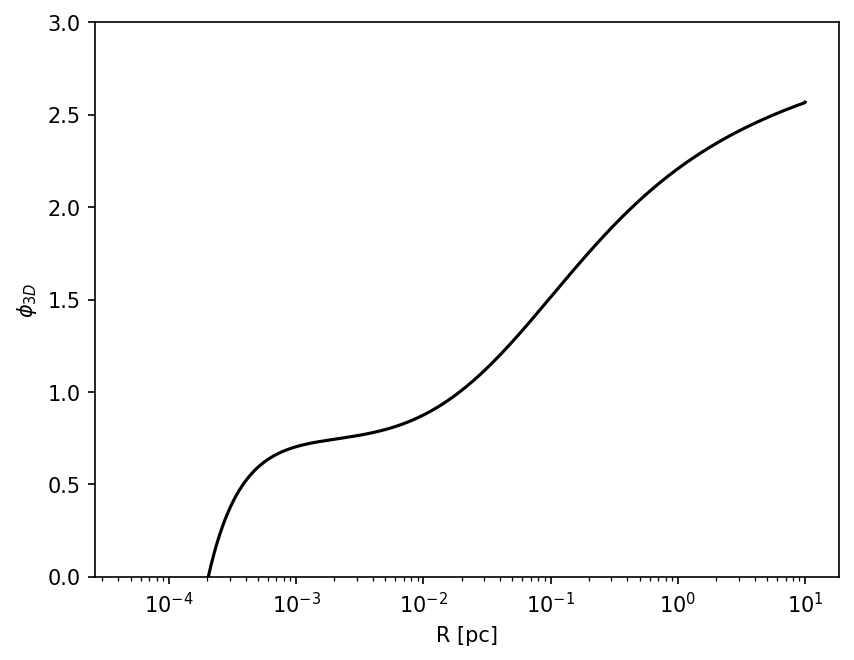

In [28]:
import matplotlib.pyplot as plt
%matplotlib inline

phi, density = model.solve_fragODE(CI, R, *args)

# you can compute the mass
mass = model.get_mass(Mo, R, phi, xi.get_xi(R))

# plot phi(R)
plt.plot(R, phi, "-k")
plt.xscale('log')
plt.ylim([0, 3])
plt.xlabel("R [pc]")
plt.ylabel("$\\phi_{3D}$")

### Integrate the fragmentation rate

Suppose you want to compare your measurement with the prediction, you need to define the limits of your spatial range, and integrate phi(R). If you have no idea on the mass transfer rate (i.e. the mass efficiency), you can test with multiple values of constant $\xi$.

In [29]:
Rmin = 1400 # AU
Rmax = 26000

xi_min, xi_max = -1, 1

ksis = np.linspace(xi_min, xi_max, 128)
phi_mean = []

idxs_r = R > 10 * model.CONVERSION.au_to_pc  # 270 ksi = 0.5
TurbCascade = model.TurbulentCascade(name='scale-free', Vo = 1000, eta = 0.38)
EOS = model.EquationOfState(name='adiabatic', temperature=10)

for ksi in ksis:
    xi = model.MassTransferRate(name='constant', ksi0=ksi)  # mass transfer rate
    args = (xi, TurbCascade, EOS)
    phi, density = model.solve_fragODE(CI, R, *args)

    phi_mean.append(model.mean_fragmentation_rate(R * model.CONVERSION.pc_to_au, phi, R1=Rmin, R2=Rmax))    


### Constrains the mass transfer rate

The plot below shows the average 3D fragmentation rate $\overline{\phi_{3D}}^{\mathrm{model}}$ predicted by your model for different mass transfer rates $\xi$. The measured fragmentation rate and its uncertainty are represented by a grey band spanning the full range of $\xi$, since no prior constraint on $\xi$ is available.

Within the context of your model, the measurement is compatible with a range of mass transfer rates. The model is compatible with the measurement wherever the predicted curve lies within the grey band. An independent estimate of $\xi$ for your cloud would allow you to compare the model prediction with the measured fragmentation rate and potentially rule out hypotheses that are inconsistent with the observations. This way you can test your model against an observable.

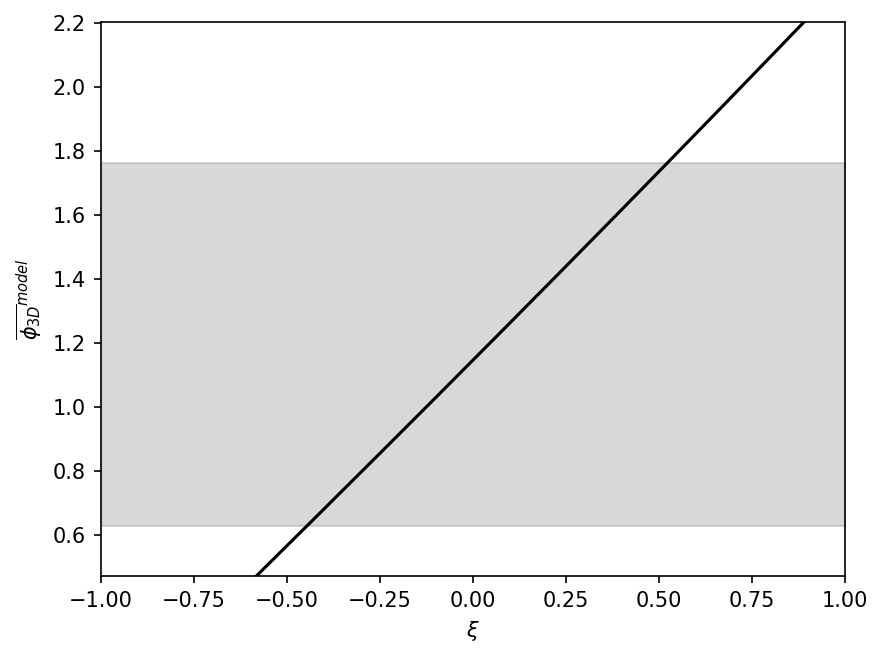

In [30]:
fig, axs = plt.subplots()

phi_mes, dphi_mes = phi3D, delta_phi3D
ymin, ymax = (phi_mes - dphi_mes) * 0.75, (phi_mes + dphi_mes) * 1.25

axs.plot(ksis, phi_mean, "-k")

axs.set_ylabel("$\\overline{\\phi_{3D}}^{model}$")
axs.set_xlabel("$\\xi$")

axs.set_xlim([xi_min, xi_max])
axs.set_ylim([ymin, ymax])

axs.fill_between(ksis, y1=phi_mes - dphi_mes, y2=phi_mes + dphi_mes, color='grey', alpha=0.3)